# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

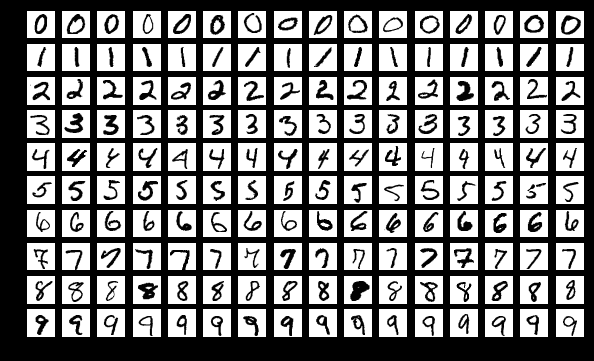

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [5]:
# %pip install torch

In [6]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


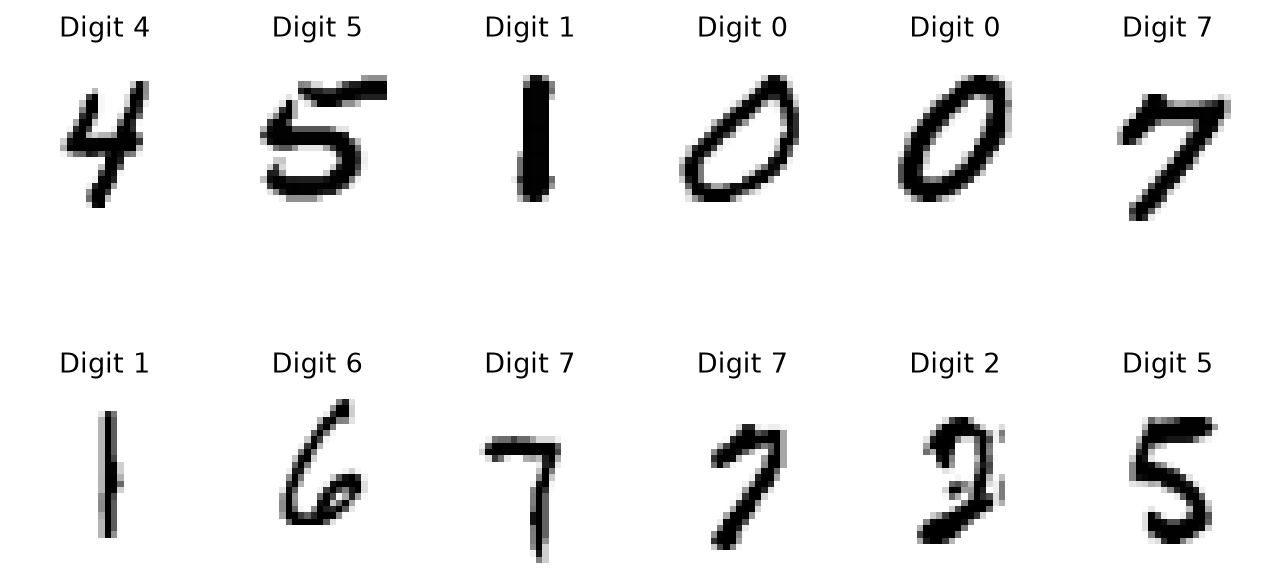

In [7]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


# MLP model
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, num_classes):
        super(NeuralNet, self).__init__()

        self.input_size = input_size
        
        # First hidden layer: z1 = W1*x + b1.
        self.l1 = nn.Linear(input_size, hidden_size1)
        # Normalize activations using batch statistics during training.
        # During evaluation, use the running statistics learned in training.
        self.bn1 = nn.BatchNorm1d(hidden_size1)
        # ReLU(z) = max(0, z): allows the network to learn nonlinear patterns.
        self.relu1 = nn.ReLU()

        # Second hidden layer: z2 = W2*h1 + b2.
        self.l2 = nn.Linear(hidden_size1, hidden_size2)
        self.bn2 = nn.BatchNorm1d(hidden_size2)
        self.relu2 = nn.ReLU()

        # Output layer: one score (logit) for each digit from 0 to 9.
        self.l3 = nn.Linear(hidden_size2, num_classes)

    def forward(self, x):
        # Pass the batch through the first hidden layer.
        out = self.l1(x)
        out = self.bn1(out)
        out = self.relu1(out)

        # Pass the result through the second hidden layer.
        out = self.l2(out)
        out = self.bn2(out)
        out = self.relu2(out)

        # Return raw scores, with shape [batch_size, 10].
        # No softmax is needed here: CrossEntropyLoss handles it internally.
        out = self.l3(out)
        return out


# Train the model
def train_model(model, optimizer, data_loader, loss_module,
                device, num_epochs=5):

    model.train()
    n_total_steps = len(data_loader)

    for epoch in range(num_epochs):
        for i, (data_inputs, data_labels) in enumerate(data_loader):
            # Images are already flattened to 784 pixels.
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            optimizer.zero_grad()

            # Forward pass
            outputs = model(data_inputs)
            loss = loss_module(outputs, data_labels)

            # Backward pass and update weights
            loss.backward()
            optimizer.step()

            if (i + 1) % 100 == 0:
                print(
                    f'Epoch [{epoch + 1}/{num_epochs}], '
                    f'Step [{i + 1}/{n_total_steps}], '
                    f'Loss: {loss.item():.4f}'
                )


# Evaluate the model
def eval_model(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for data_inputs, data_labels in data_loader:
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            outputs = model(data_inputs)

            # Select the highest-scoring digit for each image.
            # Dimension 1 contains the 10 digit scores.
            _, predicted = torch.max(outputs, 1)

            total += data_labels.size(0)
            correct += (predicted == data_labels).sum().item()

    accuracy = correct / total

    print(
        f'Accuracy of the classifier on the {total} test images: '
        f'{100 * accuracy:.2f}%'
    )


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters- Whole architecture: 784 inputs -> 500 -> 500 -> 10 outputs
input_size = 28 * 28
# 2 hidden layers of 500 neurons
hidden_size1 = 500
hidden_size2 = 500
# classes  = number of digits
num_classes = 10
# epochs = 8 -> accuracy 97,7%, epochs = 15 -> accuracy 98.39%
num_epochs = 15
batch_size = 64
learning_rate = 0.001


# Convert the already loaded data into tensors.
# Scale pixel values from [0, 255] to [-1, 1].
image_tensors = torch.tensor(images, dtype=torch.float32)
image_tensors = image_tensors / 127.5 - 1.0

# OpenML labels are strings; cross-entropy requires integer labels.
target_tensors = torch.tensor(
    targets.astype(np.int64),
    dtype=torch.long
)


# Standard MNIST split: 60,000 training and 10,000 test images.
train_dataset = TensorDataset(
    image_tensors[:60000],
    target_tensors[:60000]
)

test_dataset = TensorDataset(
    image_tensors[60000:],
    target_tensors[60000:]
)


# Data loaders
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# Initialize the model
model = NeuralNet(
    input_size, hidden_size1, hidden_size2, num_classes
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


# Train and evaluate
train_model(
    model, optimizer, train_loader, criterion, device, num_epochs
)

eval_model(model, test_loader, device)


# Classify one image from the MNIST test dataset
image, true_label = test_dataset[0]

model.eval()
with torch.no_grad():
    output = model(image.reshape(1, input_size).to(device))
    predicted_label = output.argmax(dim=1).item()

# print(
#     f'True digit: {true_label.item()}, '
#     f'predicted digit: {predicted_label}'
# )

Epoch [1/15], Step [100/938], Loss: 0.2899
Epoch [1/15], Step [200/938], Loss: 0.1448
Epoch [1/15], Step [300/938], Loss: 0.3984
Epoch [1/15], Step [400/938], Loss: 0.0735
Epoch [1/15], Step [500/938], Loss: 0.1049
Epoch [1/15], Step [600/938], Loss: 0.0656
Epoch [1/15], Step [700/938], Loss: 0.1237
Epoch [1/15], Step [800/938], Loss: 0.0383
Epoch [1/15], Step [900/938], Loss: 0.0683
Epoch [2/15], Step [100/938], Loss: 0.0715
Epoch [2/15], Step [200/938], Loss: 0.0214
Epoch [2/15], Step [300/938], Loss: 0.0603
Epoch [2/15], Step [400/938], Loss: 0.0385
Epoch [2/15], Step [500/938], Loss: 0.1559
Epoch [2/15], Step [600/938], Loss: 0.0674
Epoch [2/15], Step [700/938], Loss: 0.0098
Epoch [2/15], Step [800/938], Loss: 0.0780
Epoch [2/15], Step [900/938], Loss: 0.0700
Epoch [3/15], Step [100/938], Loss: 0.0257
Epoch [3/15], Step [200/938], Loss: 0.0519
Epoch [3/15], Step [300/938], Loss: 0.0338
Epoch [3/15], Step [400/938], Loss: 0.2134
Epoch [3/15], Step [500/938], Loss: 0.1012
Epoch [3/15